In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import zipfile
import io

In [7]:
import requests, zipfile, io
import pandas as pd

# Download MyAnimeList data from GitHub
url = 'https://github.com/Hernan4444/MyAnimeList-Database/archive/refs/heads/master.zip'
r = requests.get(url, stream=True)
z = zipfile.ZipFile(io.BytesIO(r.content))
z.extractall()

# Load the anime data
anime_data_raw = pd.read_csv('MyAnimeList-Database-master/data/anime.csv')
print(f"Raw dataset shape: {anime_data_raw.shape}")
anime_data_raw.head()

Raw dataset shape: (17562, 35)


,MAL_ID,Name,Score,Genres,English name,Japanese name,Type,Episodes,Aired,Premiered,...,Score-10,Score-9,Score-8,Score-7,Score-6,Score-5,Score-4,Score-3,Score-2,Score-1
0,1,Cowboy Bebop,8.78,"Action, Adventure, Comedy, Drama, Sci-Fi, Space",Cowboy Bebop,カウボーイビバップ,TV,26,"Apr 3, 1998 to Apr 24, 1999",Spring 1998,...,229170.0,182126.0,131625.0,62330.0,20688.0,8904.0,3184.0,1357.0,741.0,1580.0
1,5,Cowboy Bebop: Tengoku no Tobira,8.39,"Action, Drama, Mystery, Sci-Fi, Space",Cowboy Bebop:The Movie,カウボーイビバップ 天国の扉,Movie,1,"Sep 1, 2001",Unknown,...,30043.0,49201.0,49505.0,22632.0,5805.0,1877.0,577.0,221.0,109.0,379.0
2,6,Trigun,8.24,"Action, Sci-Fi, Adventure, Comedy, Drama, Shounen",Trigun,トライガン,TV,26,"Apr 1, 1998 to Sep 30, 1998",Spring 1998,...,50229.0,75651.0,86142.0,49432.0,15376.0,5838.0,1965.0,664.0,316.0,533.0
3,7,Witch Hunter Robin,7.27,"Action, Mystery, Police, Supernatural, Drama, ...",Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),TV,26,"Jul 2, 2002 to Dec 24, 2002",Summer 2002,...,2182.0,4806.0,10128.0,11618.0,5709.0,2920.0,1083.0,353.0,164.0,131.0
4,8,Bouken Ou Beet,6.98,"Adventure, Fantasy, Shounen, Supernatural",Beet the Vandel Buster,冒険王ビィト,TV,52,"Sep 30, 2004 to Sep 29, 2005",Fall 2004,...,312.0,529.0,1242.0,1713.0,1068.0,634.0,265.0,83.0,50.0,27.0


In [9]:
# Preprocessing — Do NOT modify this cell
columns_to_keep = ['MAL_ID', 'Name', 'Score', 'Type', 'Episodes',
                   'Members', 'Completed', 'Watching', 'Dropped', 'Popularity']
anime_data = anime_data_raw[columns_to_keep].copy()

# Remove rows where key metric columns have missing or zero values
anime_data = anime_data.dropna(subset=['Members', 'Completed', 'Watching'])
anime_data = anime_data[(anime_data['Members'] > 0) &
                        (anime_data['Completed'] > 0) &
                        (anime_data['Watching'] > 0)]
anime_data = anime_data.reset_index(drop=True)
print(f"Dataset shape after preprocessing: {anime_data.shape}")
anime_data.head()

Dataset shape after preprocessing: (16943, 10)


,MAL_ID,Name,Score,Type,Episodes,Members,Completed,Watching,Dropped,Popularity
0,1,Cowboy Bebop,8.78,TV,26,1251960,718161,105808,26678,39
1,5,Cowboy Bebop: Tengoku no Tobira,8.39,Movie,1,273145,208333,4143,770,518
2,6,Trigun,8.24,TV,26,558913,343492,29113,13925,201
3,7,Witch Hunter Robin,7.27,TV,26,94683,46165,4300,5378,1467
4,8,Bouken Ou Beet,6.98,TV,52,13224,7314,642,1108,4369


In [11]:
def homework(anime_data, metric_column, n):
    # Step 1: Sort the data so the biggest values are at the very top.
    # ascending=False means we go from Highest to Lowest.
    sorted_data = anime_data.sort_values(by=metric_column, ascending=False)
    
    # Step 2: Give each row a ranking number (1st, 2nd, 3rd...) based on the column.
    # We use method='first' so that if two anime have the exact same score, 
    # the computer doesn't get confused and just ranks whichever one it saw first.
    ranks = sorted_data[metric_column].rank(method='first', ascending=False)
    
    # Let's create the nametags for our groups: "Group 1", "Group 2", all the way up to "n".
    group_labels = []
    for i in range(1, n + 1):
        group_labels.append(f"Group {i}")
        
    # Now we use 'pd.qcut()' to chop our ranked data into 'n' equal-sized buckets.
    # Think of this like dealing the ranked cards evenly into 'n' piles.
    groups = pd.qcut(ranks, q=n, labels=group_labels)
    
    # Step 3: Find out the grand total of the entire metric_column for all anime combined.
    grand_total = sorted_data[metric_column].sum()
    
    # Now, let's find the total score for just the anime inside each specific group.
    group_totals = sorted_data.groupby(groups)[metric_column].sum()
    
    # To get the percentage (proportion), we just divide each group's total by the grand total.
    proportions = group_totals / grand_total
    
    # Step 4: Finally, sort our groups so the one with the biggest percentage is at the top.
    final_result = proportions.sort_values(ascending=False)
    
    # Return our finished pandas.Series!
    return final_result

In [13]:
# Run this cell after completing homework().
your_answer = homework(anime_data, "Completed", 10)
display(your_answer)


Completed
Group 1     0.834754
Group 2     0.107360
Group 3     0.032924
Group 4     0.013563
Group 5     0.006311
Group 6     0.002829
Group 7     0.001217
Group 8     0.000593
Group 9     0.000317
Group 10    0.000133
Name: Completed, dtype: float64

In [15]:
case_2_data = pd.DataFrame({
    "Completed": [40, 30, 20, 10],
})
case_2_answer = homework(case_2_data, "Completed", 2)
display(case_2_answer)


Completed
Group 1    0.7
Group 2    0.3
Name: Completed, dtype: float64

In [17]:
case_3_data = pd.DataFrame({
    "Members": [60, 50, 40, 30, 20, 10],
})
case_3_answer = homework(case_3_data, "Members", 3)
display(case_3_answer)


Members
Group 1    0.523810
Group 2    0.333333
Group 3    0.142857
Name: Members, dtype: float64

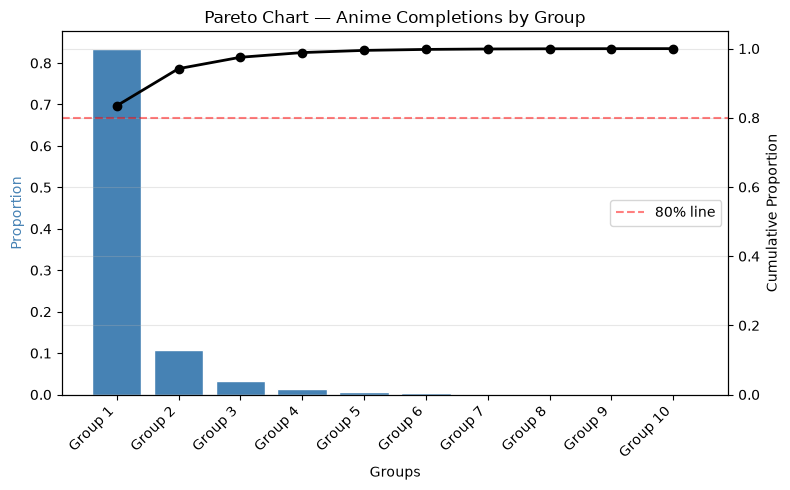

In [18]:
N = 10
data = homework(anime_data, 'Completed', N)

fig, ax1 = plt.subplots(figsize=(8, 5))

data_num = len(data)
cum_per = np.cumsum(data)

# Bar chart — proportion per group
ax1.bar(range(data_num), data, color='steelblue', edgecolor='white')
ax1.set_xticks(range(data_num))
ax1.set_xticklabels(data.index, rotation=45, ha='right')

# Line chart — cumulative proportion
ax2 = ax1.twinx()
ax2.plot(range(data_num), cum_per, color='k', marker='o', linewidth=2)
ax2.set_ylim([0, 1.05])
ax2.axhline(y=0.8, color='r', linestyle='--', alpha=0.5, label='80% line')
ax2.grid(True, which='both', axis='y', alpha=0.3)

ax1.set_xlabel('Groups')
ax1.set_ylabel('Proportion', color='steelblue')
ax2.set_ylabel('Cumulative Proportion', color='k')
ax2.legend(loc='center right')
plt.title('Pareto Chart — Anime Completions by Group')
plt.tight_layout()
plt.show()